# GNSS Spoofing Detection by AoA Comparison

Paper flow of *GNSS Spoofing Detection by Estimating Angle of Arrival based on Carrier Phase Double Difference Measurements* (Hoang Van, Nguyen Dinh) on one two-receiver u-blox capture with a partly spoofed sky. The notebook reads top to bottom: data check → rig check → DD-method AoA → decision; diagnostics are collected at the end.

**Method in eight lines**

1. Parse RXM-RAWX, NAV-PVT and NAV-SAT from both receivers; synchronize RAWX epochs by receiver time of week.
2. Carrier phase per PRN: `cpMes + nano * 1e-9 * doMes` (Eq. 8), kept only where `cpValid = 1` and `halfCyc = 1`.
3. Receiver single difference (Eq. 9), then satellite double difference against one reference PRN (Eq. 14).
4. Fractional DD = DD − round(DD) (Eq. 18); with a one-wavelength baseline this fixes cos α modulo one.
5. Reference-angle anchor α_r: baseline-relative AoA of the reference PRN from Receiver 1 NAV-SAT azimuth/elevation.
6. Eq. 21 candidates cos α_i = Φ_i + m + cos α_r for m ∈ {−2, …, 2}; only |cos α| ≤ 1 survives.
7. Branch selection: per satellite by Algorithm 1 (DP over smoothness); for the spoof group jointly (one source ⇒ one direction). Costs are scored in direction cosine, where the branches are exact unit shifts of each other.
8. Decision: |DD-method AoA − ephemeris-based AoA| > 10° flags a PRN; spoof PRNs additionally collapse onto one AoA while their ephemeris-based AoAs stay distinct.

| Artifact | Paper meaning |
| --- | --- |
| `carrier_phase_cycles` | Eq. 8 carrier phase observable |
| `single_difference_cycles`, `double_difference_cycles` | Eq. 9 receiver single difference, Eq. 14 satellite double difference |
| `fractional_dd_cycles` | Eq. 18 fractional DD |
| `candidate_aoa_deg`, `candidate_cos_alpha` | Eq. 21 branch candidates for m ∈ {−2, …, 2} |
| `joint_source_aoa_deg`, `joint_source_branch`, `joint_source_ambiguity` | Selected branch per spoof PRN, and how it was chosen (`chosen_by`) |
| `spoof_branch_detection` | Both branches against the ephemeris-based AoA with the 10° test |
| `ephemeris_aoa_rx1_deg` | Baseline-relative AoA from receiver NAV-SAT azimuth/elevation |


In [1]:
from pathlib import Path
import importlib

import matplotlib.pyplot as plt
import pandas as pd

import aoa_pipeline
importlib.reload(aoa_pipeline)

from aoa_pipeline import (
    DatasetConfig,
    compute_navsat_geometry_by_synced_epoch,
    compute_single_difference,
    fit_baseline_azimuth,
    plot_aoa_tracks,
    plot_fractional_dd,
    plot_spoof_branch_summary,
    plot_sv_used_timeline,
    plot_valid_m_candidates,
    probe_capture,
    run_paper_scenario,
    summarize_pairwise_single_difference_collapse,
)

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 160)

## Configuration

The capture folder must hold one `COM3*.ubx` (Receiver 1) and one `COM4*.ubx` (Receiver 2). `SPOOF_SVIDS` is the PRN group the spoofer transmits; the DD reference is the best non-spoof PRN unless `REFERENCE_SVID` overrides it. `SINGLE_DIFFERENCE_ORDER` and `NAVSAT_AZIMUTH_BIAS_DEG` describe the rig (which antenna is which end of the baseline, and the baseline's azimuth); the rig check in §2 tells you whether they fit the authentic satellites. `PRIOR_AOA_DEG` is the only way to break the one-wavelength branch tie (§4); leave it `None` unless the set-up angle is known.


In [2]:
DATASET_DIR = Path("dataset/sp-partial-28-08/v4")  # folder holding COM3*.ubx (Receiver 1) and COM4*.ubx (Receiver 2)
SPOOF_SVIDS = (10, 23, 24, 25)                     # PRNs transmitted by the spoofer
REFERENCE_SVID = None                              # DD reference PRN; None = automatic, best non-spoof PRN
SINGLE_DIFFERENCE_ORDER = "rx2-rx1"                # baseline polarity: "rx1-rx2" or "rx2-rx1"
NAVSAT_AZIMUTH_BIAS_DEG = 0.0                      # baseline azimuth assumed when NAV-SAT az/el becomes a baseline-relative AoA
BASELINE_OVER_WAVELENGTH = 1.0                     # D / lambda; 1.0 is the paper's one-wavelength baseline
PRIOR_AOA_DEG = None                               # declared spoofer AoA prior in degrees; None = report the branch tie as unresolved
CONVERGENCE_THRESHOLD_DEG = 5.0                    # spoof PRNs within this many degrees of each other form one cluster
DETECTION_THRESHOLD_DEG = 10.0                     # paper threshold on |DD-method AoA - ephemeris-based AoA|
RUN_FULL = True                                    # False = first 500 synchronized epochs only
OUTPUT_ROOT = Path("outputs/aoa_paper")


def receiver_paths(folder: Path) -> tuple[Path, Path]:
    rx1 = sorted(folder.glob("COM3*.ubx"))
    rx2 = sorted(folder.glob("COM4*.ubx"))
    if len(rx1) != 1 or len(rx2) != 1:
        raise FileNotFoundError(f"Expected exactly one COM3*.ubx and one COM4*.ubx in {folder}; found {rx1} and {rx2}")
    return rx1[0], rx2[0]


RECEIVER1_PATH, RECEIVER2_PATH = receiver_paths(DATASET_DIR)
try:
    DATASET_NAME = DATASET_DIR.resolve().relative_to(Path("dataset").resolve()).as_posix()
except ValueError:
    DATASET_NAME = DATASET_DIR.name
OUTPUT_DIR = OUTPUT_ROOT / DATASET_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.DataFrame(
    [
        {
            "dataset": DATASET_NAME,
            "receiver1": RECEIVER1_PATH.name,
            "receiver2": RECEIVER2_PATH.name,
            "spoof_svids": SPOOF_SVIDS,
            "reference_svid": "automatic non-spoof" if REFERENCE_SVID is None else REFERENCE_SVID,
            "single_difference_order": SINGLE_DIFFERENCE_ORDER,
            "navsat_azimuth_bias_deg": NAVSAT_AZIMUTH_BIAS_DEG,
            "baseline_over_wavelength": BASELINE_OVER_WAVELENGTH,
            "prior_aoa_deg": "none (report unresolved)" if PRIOR_AOA_DEG is None else PRIOR_AOA_DEG,
            "detection_threshold_deg": DETECTION_THRESHOLD_DEG,
            "run_full": RUN_FULL,
            "output_dir": str(OUTPUT_DIR),
        }
    ]
).T.rename(columns={0: "value"})

,value
dataset,sp-partial-28-08/v4
receiver1,COM3___9600_260828_111540.ubx
receiver2,COM4___9600_260828_111534.ubx
spoof_svids,"(10, 23, 24, 25)"
reference_svid,automatic non-spoof
single_difference_order,rx2-rx1
navsat_azimuth_bias_deg,0.0
baseline_over_wavelength,1.0
prior_aoa_deg,none (report unresolved)
detection_threshold_deg,10.0


## 1. Data check

This is what would have stopped v1/v2 (no RXM-RAWX on Receiver 2) and v3, v6, v7 (the spoof PRNs never held valid carrier phase in both receivers at the same time) before any angle was computed. The flow needs every spoof PRN valid in both receivers over one continuous run of epochs. `probe.raise_for_problems()` stops the notebook with the reason; warnings (a spoof PRN dropped, a thin window) let it continue.


In [3]:
probe = probe_capture(RECEIVER1_PATH, RECEIVER2_PATH, spoof_svids=SPOOF_SVIDS)

print("UBX message inventory per receiver")
display(probe.message_inventory)

print("Spoof PRNs: tracking quality per receiver (usable phase = cpValid=1 and halfCyc=1)")
if not probe.receiver_svid_summary.empty:
    display(probe.receiver_svid_summary.loc[probe.receiver_svid_summary["spoof"]].round(1))

print("Spoof PRNs: valid carrier phase in both receivers")
display(probe.spoof_phase_summary)
print(
    f"epochs with every usable spoof PRN valid in both receivers: {probe.all_spoof_valid_epoch_count}; "
    f"longest continuous run: {probe.longest_all_spoof_valid_run}"
)
for warning in probe.warnings:
    print(f"WARNING: {warning}")
probe.raise_for_problems()

USABLE_SPOOF_SVIDS = probe.usable_spoof_svids
probe.message_inventory.to_csv(OUTPUT_DIR / "paper_capture_message_inventory.csv")
probe.spoof_phase_summary.to_csv(OUTPUT_DIR / "paper_capture_spoof_phase.csv", index=False)
print(f"usable spoof group: {USABLE_SPOOF_SVIDS}")

UBX message inventory per receiver


,file,size_kb,RXM-RAWX,NAV-PVT,NAV-SAT,NAV-SIG,RXM-SFRBX,rawx_epochs,rawx_span_s
receiver,,,,,,,,,
Receiver 1,COM3___9600_260828_111540.ubx,2854.3,406,406,404,406,2086,406,405.0
Receiver 2,COM4___9600_260828_111534.ubx,1813.6,386,386,378,103,1112,386,385.0


Spoof PRNs: tracking quality per receiver (usable phase = cpValid=1 and halfCyc=1)


,svid,receiver,rawx_rows,usable_phase_rows,mean_cno,max_locktime_s,sv_used_epochs,median_elev_deg,median_azim_deg,spoof
4,10,Receiver 1,60,31,38.5,55.0,0,52.0,161.0,True
6,23,Receiver 1,63,31,41.7,45.0,0,65.0,95.0,True
7,24,Receiver 1,65,31,41.2,45.0,0,55.0,56.0,True
17,10,Receiver 2,25,12,35.8,10.3,0,52.0,161.0,True
19,23,Receiver 2,41,12,29.7,10.3,0,64.0,95.0,True
20,24,Receiver 2,26,12,36.1,10.4,14,55.0,56.0,True


Spoof PRNs: valid carrier phase in both receivers


,svid,rx1_valid_epochs,rx2_valid_epochs,common_valid_epochs,longest_common_run,usable,common_segments,rx1_segments,rx2_segments
0,10,12,12,12,7,True,TOW 472581-472584 (4 ep); TOW 472591-472597 (7 ep); TOW 472603-472603 (1 ep),TOW 472581-472584 (4 ep); TOW 472591-472597 (7 ep); TOW 472603-472603 (1 ep),TOW 472581-472584 (4 ep); TOW 472591-472597 (7 ep); TOW 472603-472603 (1 ep)
1,23,12,12,12,7,True,TOW 472581-472584 (4 ep); TOW 472591-472597 (7 ep); TOW 472603-472603 (1 ep),TOW 472581-472584 (4 ep); TOW 472591-472597 (7 ep); TOW 472603-472603 (1 ep),TOW 472581-472584 (4 ep); TOW 472591-472597 (7 ep); TOW 472603-472603 (1 ep)
2,24,12,12,12,7,True,TOW 472581-472584 (4 ep); TOW 472591-472597 (7 ep); TOW 472603-472603 (1 ep),TOW 472581-472584 (4 ep); TOW 472591-472597 (7 ep); TOW 472603-472603 (1 ep),TOW 472581-472584 (4 ep); TOW 472591-472597 (7 ep); TOW 472603-472603 (1 ep)
3,25,0,0,0,0,False,,,


epochs with every usable spoof PRN valid in both receivers: 12; longest continuous run: 7
usable spoof group: (10, 23, 24)


## 2. Rig check

For authentic PRNs i, j the wrapped inter-satellite double difference must equal wrap(k (cos α_i − cos α_j)) with cos α = cos(el) · cos(az − az_b). Fitting the baseline azimuth az_b over the authentic PRNs needs no reference PRN, no anchor and no branch, so it is the independent test of `SINGLE_DIFFERENCE_ORDER` and `NAVSAT_AZIMUTH_BIAS_DEG`. A fit near the configured bias confirms the rig; a fit near bias + 180° means the antennas are swapped (`rx1-rx2` with bias 0 and `rx2-rx1` with bias 180 describe the same rig). The 08-30 afternoon captures (v8, v9) needed this. Random data give a median residual near 0.25 cycles; this rig fits at 0.05–0.09. D/λ is fitted as well but kept at the configured value: the 08-28 captures fit 1.05–1.10, which is not confirmed.

The last table is the anchor-free common-source evidence: median |wrap(SD_i − SD_j)| between spoof PRNs over every common epoch of the capture. Two signals from one source differ by an integer number of cycles only.


In [4]:
single_difference = compute_single_difference(probe.carrier_phase, order=SINGLE_DIFFERENCE_ORDER)
elevation, azimuth = compute_navsat_geometry_by_synced_epoch(
    probe.synced.epochs, probe.observations[0].navsat, epoch_tow_column="rcvTow_rx1"
)
rig = fit_baseline_azimuth(
    single_difference,
    elevation,
    azimuth,
    exclude_svids=SPOOF_SVIDS,
    baseline_over_wavelength=BASELINE_OVER_WAVELENGTH,
    configured_azimuth_deg=NAVSAT_AZIMUTH_BIAS_DEG,
)
display(rig.to_frame().T.rename(columns={0: "value"}))
print("best baseline azimuth per D/lambda")
display(rig.best_per_ratio.round(4))
print("per authentic PRN, median |residual| at the fit (cycles):", rig.per_svid_residual_cycles.round(3).to_dict())
print(("OK: " if rig.consistent else "WARNING: ") + rig.recommendation)
rig.to_frame().to_csv(OUTPUT_DIR / "paper_rig_check.csv", index=False)

print("spoof group, median |wrap(SD_i - SD_j)| over all common epochs (cycles)")
sd_collapse = summarize_pairwise_single_difference_collapse(single_difference, USABLE_SPOOF_SVIDS)
display(sd_collapse.round(4))
sd_collapse.to_csv(OUTPUT_DIR / "paper_spoof_single_difference_collapse.csv", index=False)

,value
authentic_svids,"3,4,8,9,16,26,27,28,31"
baseline_over_wavelength,1.0
configured_azimuth_deg,0.0
fitted_azimuth_deg,352.0
azimuth_difference_deg,-8.0
fitted_residual_cycles,0.053937
configured_residual_cycles,0.105637
opposite_residual_cycles,0.292193
consistent,True
recommendation,"configured baseline azimuth 0 deg is consistent with the authentic PRNs (fit 352 deg, median residual 0.054 cycles at the fit, 0.106 as configured)."


best baseline azimuth per D/lambda


,baseline_over_wavelength,azimuth_deg,median_abs_residual_cycles,pct_le_0p05_cycles
0,0.90,352.0,0.1074,21.6936
1,0.95,352.0,0.0787,31.2899
2,1.00,352.0,0.0539,46.6899
3,1.05,351.0,0.0418,58.5201
4,1.10,351.0,0.0506,49.3543


per authentic PRN, median |residual| at the fit (cycles): {3: 0.054, 4: 0.05, 8: 0.052, 9: 0.087, 16: 0.044, 26: 0.057, 27: 0.048, 28: 0.053, 31: 0.05}
OK: configured baseline azimuth 0 deg is consistent with the authentic PRNs (fit 352 deg, median residual 0.054 cycles at the fit, 0.106 as configured).
spoof group, median |wrap(SD_i - SD_j)| over all common epochs (cycles)


,pair,left_svid,right_svid,epoch_count,median_abs_wrapped_sd_diff_cycles,p90_abs_wrapped_sd_diff_cycles
0,10-23,10,23,12,0.0095,0.0314
1,10-24,10,24,12,0.0146,0.0304
2,23-24,23,24,12,0.0087,0.0301


## 3. DD-method AoA

`run_paper_scenario` runs a probe pass to pick the reference PRN and the longest epoch window in which all spoof PRNs are valid, takes α_r as the median Receiver 1 NAV-SAT AoA of the reference PRN inside that window, computes the Eq. 21 candidates, selects the spoof PRNs' branches jointly and every other PRN's branch per satellite, and writes all tables and figures to `outputs/aoa_paper/<dataset>/`.


In [5]:
SCENARIO_CONFIG = DatasetConfig(
    name=DATASET_NAME,
    receiver1_path=RECEIVER1_PATH,
    receiver2_path=RECEIVER2_PATH,
    alpha_r_deg=None,
    reference_svid=REFERENCE_SVID,
    selected_svids=USABLE_SPOOF_SVIDS,
    excluded_reference_svids=SPOOF_SVIDS,
    reference_required_svids=USABLE_SPOOF_SVIDS,
    start_index=0,
    length=None if RUN_FULL else 500,
    sync_tow_decimals=0,
    use_navpvt_time_correction=True,
    single_difference_order=SINGLE_DIFFERENCE_ORDER,
    baseline_over_wavelength=BASELINE_OVER_WAVELENGTH,
    branch_metric="direction_cosine",
    navsat_azimuth_bias_deg=NAVSAT_AZIMUTH_BIAS_DEG,
    output_root=OUTPUT_ROOT,
)

scenario = run_paper_scenario(
    SCENARIO_CONFIG,
    partial_spoof_enabled=True,
    spoof_svids=USABLE_SPOOF_SVIDS,
    convergence_threshold_deg=CONVERGENCE_THRESHOLD_DEG,
    detection_threshold_deg=DETECTION_THRESHOLD_DEG,
    prior_aoa_deg=PRIOR_AOA_DEG,
    save_outputs=True,
)
result = scenario.analysis_result
all_satellite_result = scenario.all_satellite_result
scenario.run_summary.T.rename(columns={0: "value"})

,value
dataset,sp-partial-28-08/v4
partial_spoof_enabled,True
spoof_svids,"(10, 23, 24)"
excluded_analysis_svids,()
reference_svid,16
reference_alpha_deg,66.556255
navsat_azimuth_bias_deg,0.0
single_difference_order,rx2-rx1
baseline_over_wavelength,1.0
branch_metric,direction_cosine


## 4. Result

One row per spoof PRN: the ephemeris-based AoA (what a real satellite at that PRN's position would show), the DD-method AoA on the selected Eq. 21 branch and on the alternative branch, how the branch was chosen, and the 10° test on each. `spoof_flag_all_branches` is the verdict that does not depend on the branch.

Two ways to misread the numbers:

- **Branch ambiguity.** With D = λ the fractional DD fixes cos α only modulo one, so every PRN has two valid candidates, c and c − sign(c), and the whole spoof group shares the same mirror. Their spread and step costs are identical in direction cosine; a static capture carries no information about m. `chosen_by = data` appears only when the mirror leaves [−1, 1] (D = λ/2, or a rig rotated during the capture); `prior` means `PRIOR_AOA_DEG` picked the branch; `unresolved` means the smallest-|m| combination is shown and the alternative is just as consistent with the data, so both must be reported. The previous notebook scored branches in degrees, where the same phase noise looks smaller near 90°, and therefore always picked the branch nearer 90° (v4: 102.5° instead of 38.3°, v5: 78.4° instead of 143°).
- **Rig polarity.** α_r and the ephemeris-based AoA assume the configured baseline azimuth and receiver order. If the rig check in §2 warned, every absolute angle here is wrong even though the collapse still holds; the collapse metrics and `spoof_flag_all_branches` are the only anchor-free statements.


branch selection: chosen_by = unresolved, ambiguous = True, selected m = (0,0,0), alternative m = (-1,-1,-1), tie tolerance = 0.107 in direction cosine
The data of this static one-wavelength capture do not decide the branch: both DD-method AoA values below are equally consistent with the measurements. Set PRIOR_AOA_DEG to the declared set-up angle to pick one, and say so when reporting.


,svid,ephemeris_aoa_deg,selected_m,selected_aoa_deg,selected_std_deg,alternative_m,alternative_aoa_deg,alternative_std_deg,chosen_by,abs_diff_selected_deg,abs_diff_alternative_deg,spoof_flag_selected,spoof_flag_all_branches
0,10,124.44,0,38.34,1.77,-1,102.46,1.13,unresolved,86.10,21.98,True,True
1,23,90.42,0,37.75,1.07,-1,102.08,0.67,unresolved,52.68,11.66,True,True
2,24,72.76,0,38.63,0.93,-1,102.64,0.60,unresolved,34.13,29.88,True,True


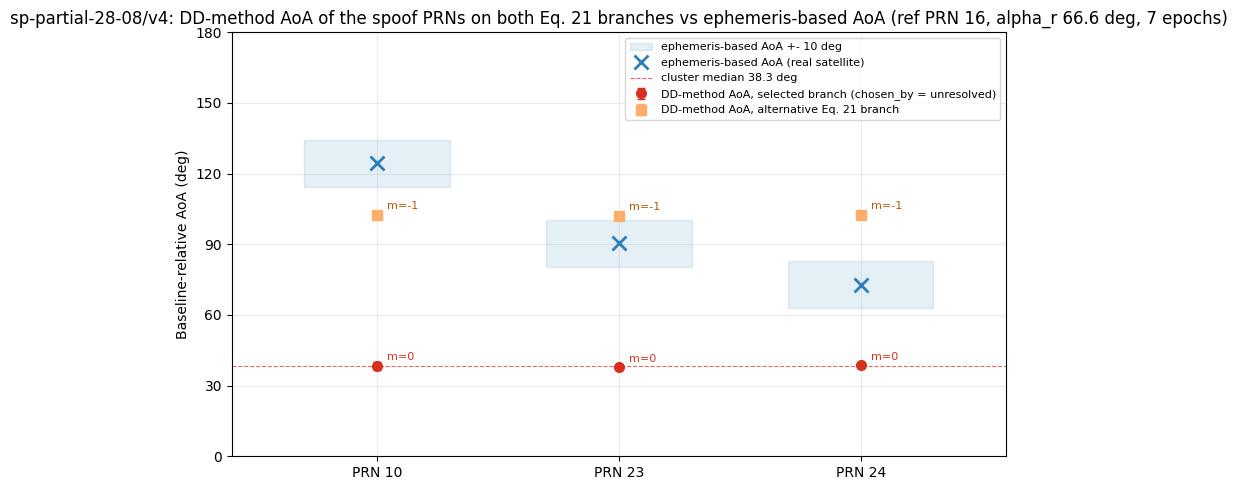

cluster of spoof PRNs on the selected branch


,cluster_svids,cluster_size,epoch_count,median_aoa_deg,mean_aoa_deg,std_epoch_median_aoa_deg,median_spread_deg,p90_spread_deg,threshold_deg
0,"10,23,24",3,7,38.34,38.26,1.27,1.44,3.24,5.0


common-source collapse of the fractional DD inside the window (cycles, branch-free)


,usable_epoch_count,total_epoch_count,median_dispersion_cycles,p90_dispersion_cycles,median_mad_cycles,pct_epochs_dispersion_le_0p05_cycles,pct_epochs_dispersion_le_0p1_cycles,pct_epochs_dispersion_le_0p15_cycles
0,7,7,0.0156,0.035,0.0026,100.0,100.0,100.0


In [6]:
if scenario.joint_source_ambiguity.empty:
    raise RuntimeError("joint-source selection produced no epochs; check the data check above")
ambiguity = scenario.joint_source_ambiguity.iloc[0]
print(
    f"branch selection: chosen_by = {ambiguity['chosen_by']}, ambiguous = {bool(ambiguity['ambiguous'])}, "
    f"selected m = ({ambiguity['selected_branches']}), alternative m = ({ambiguity['alternative_branches']}), "
    f"tie tolerance = {ambiguity['tie_tolerance']:.3f} in direction cosine"
)
if ambiguity["chosen_by"] == "unresolved":
    print(
        "The data of this static one-wavelength capture do not decide the branch: both DD-method AoA values below "
        "are equally consistent with the measurements. Set PRIOR_AOA_DEG to the declared set-up angle to pick one, "
        "and say so when reporting."
    )
elif ambiguity["chosen_by"] == "prior":
    print(f"The branch was picked by the declared prior of {PRIOR_AOA_DEG} deg, not by the data.")

detection = scenario.spoof_branch_detection
display(
    detection[
        [
            "svid",
            "ephemeris_aoa_deg",
            "selected_m",
            "selected_aoa_deg",
            "selected_std_deg",
            "alternative_m",
            "alternative_aoa_deg",
            "alternative_std_deg",
            "chosen_by",
            "abs_diff_selected_deg",
            "abs_diff_alternative_deg",
            "spoof_flag_selected",
            "spoof_flag_all_branches",
        ]
    ].round(2)
)

cluster_median = float(scenario.cluster_summary["median_aoa_deg"].iloc[0]) if not scenario.cluster_summary.empty else None
fig = plot_spoof_branch_summary(
    detection,
    prior_aoa_deg=PRIOR_AOA_DEG,
    cluster_median_aoa_deg=cluster_median,
    title=(
        f"{DATASET_NAME}: DD-method AoA of the spoof PRNs on both Eq. 21 branches vs ephemeris-based AoA "
        f"(ref PRN {result.reference_svid}, alpha_r {scenario.run_summary['reference_alpha_deg'].iloc[0]:.1f} deg, "
        f"{len(result.epochs)} epochs)"
    ),
)
display(fig)
plt.close(fig)

print("cluster of spoof PRNs on the selected branch")
display(scenario.cluster_summary.round(2))
print("common-source collapse of the fractional DD inside the window (cycles, branch-free)")
display(result.collapse_metrics.round(4))

## 5. Diagnostics

Intermediate steps in pipeline order: the window and the reference ranking, the fractional DD of the window, the joint-source track, the per-epoch branch ambiguity, every valid m per satellite with the ephemeris overlay (the plot to look at when a branch looks wrong), the authentic PRNs on their ephemeris-aligned branch, and svUsed over the full NAV-SAT timeline of both receivers.


analysis window (synchronized epochs)


,epoch_index,source_epoch_index,rcvTow_rx1,rcvTow_rx2,tow_delta_s
0,0,10,472590.997,472590.999,-0.002
1,1,11,472591.997,472591.999,-0.002
2,2,12,472592.997,472592.999,-0.002
3,3,13,472593.997,472593.999,-0.002
4,4,14,472594.997,472594.999,-0.002
5,5,15,472595.997,472595.999,-0.002
6,6,16,472596.997,472596.999,-0.002


reference ranking of the non-spoof PRNs (probe pass)


,svid,valid_epoch_count,longest_continuous_run,mean_cno,median_abs_phase_step_cycles,manual_override
0,16,12,7,43.416667,456.763968,False
1,31,12,7,42.833333,456.785225,False
2,26,12,7,41.000000,456.760583,False
3,27,12,7,40.250000,456.757472,False
4,9,12,7,40.000000,456.774906,False
5,4,12,7,39.500000,456.763263,False
6,28,12,7,38.833333,456.777049,False
7,8,12,7,37.458333,456.758319,False


reference-angle anchor of PRN 16 inside the window (Receiver 1 NAV-SAT)


,reference_elev_deg,reference_azim_deg,reference_alpha_deg
count,7.0,7.0,7.00
mean,66.0,348.0,66.56
min,66.0,348.0,66.56
max,66.0,348.0,66.56


fractional DD (cycles) of the spoof PRNs inside the window


,10,23,24
epoch_index,,,
0,0.3748,0.3771,0.3833
1,0.3685,0.4012,0.3928
2,0.3865,0.3857,0.3983
3,0.3967,0.3952,0.3880
4,0.4137,0.4098,0.3792
5,0.3571,0.3929,0.3675
6,0.3945,0.3815,0.3789


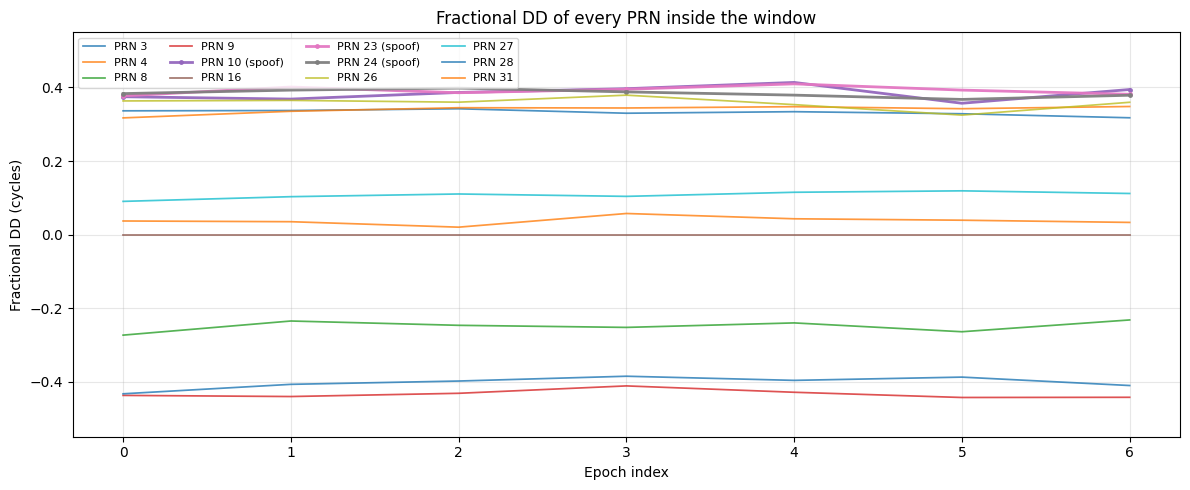

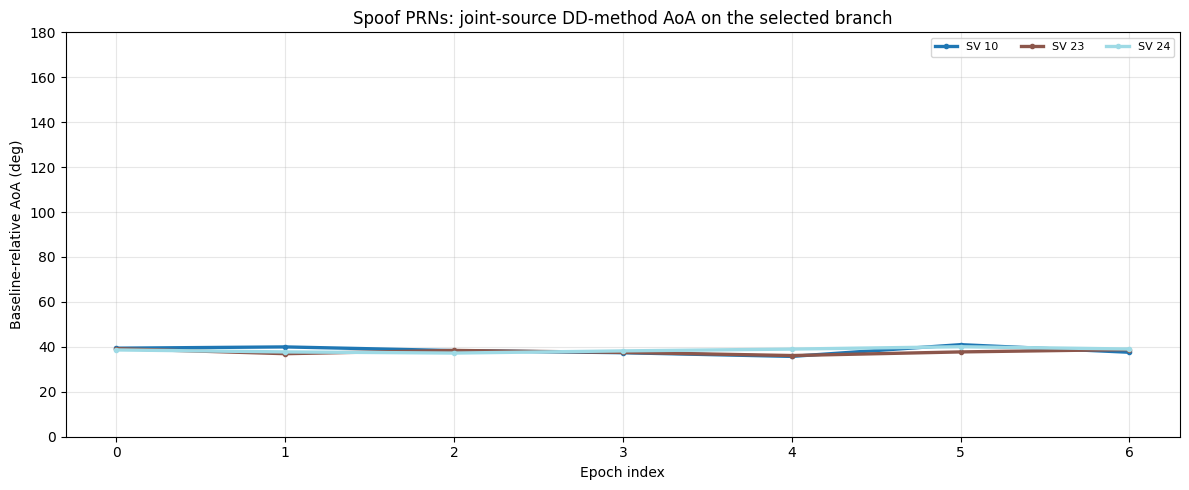

joint-source branch ambiguity per epoch (costs in direction cosine)


,epoch_index,dp_branches,dp_cost,selected_branches,selected_cost,alternative_shift,alternative_branches,alternative_cost,alternative_excess,alternative_mean_excess,tied_shifts,ambiguous,chosen_by,tie_tolerance,metric,prior_aoa_deg
0,0,"-1,-1,-1",0.0340,"0,0,0",0.0340,-1,"-1,-1,-1",0.0340,0.0,0.0,-1,True,unresolved,0.1069,direction_cosine,NaN
1,1,"-1,-1,-1",0.1443,"0,0,0",0.1443,-1,"-1,-1,-1",0.1443,0.0,0.0,-1,True,unresolved,0.1069,direction_cosine,NaN
2,2,"-1,-1,-1",0.0634,"0,0,0",0.0634,-1,"-1,-1,-1",0.0634,0.0,0.0,-1,True,unresolved,0.1069,direction_cosine,NaN
3,3,"-1,-1,-1",0.0448,"0,0,0",0.0448,-1,"-1,-1,-1",0.0448,0.0,0.0,-1,True,unresolved,0.1069,direction_cosine,NaN
4,4,"-1,-1,-1",0.1516,"0,0,0",0.1516,-1,"-1,-1,-1",0.1516,0.0,0.0,-1,True,unresolved,0.1069,direction_cosine,NaN
5,5,"-1,-1,-1",0.1715,"0,0,0",0.1715,-1,"-1,-1,-1",0.1715,0.0,0.0,-1,True,unresolved,0.1069,direction_cosine,NaN
6,6,"-1,-1,-1",0.0824,"0,0,0",0.0824,-1,"-1,-1,-1",0.0824,0.0,0.0,-1,True,unresolved,0.1069,direction_cosine,NaN


every valid Eq. 21 branch of the spoof PRNs inside the window


,svid,branch,epoch_count,median_aoa_deg,mean_aoa_deg,std_aoa_deg,min_aoa_deg,max_aoa_deg,median_cos_alpha
0,10,-1,7,102.46,102.57,1.13,100.86,104.19,-0.22
1,10,0,7,38.34,38.49,1.77,35.75,40.98,0.78
2,23,-1,7,102.08,102.14,0.67,101.09,103.01,-0.21
3,23,0,7,37.75,37.83,1.07,36.13,39.20,0.79
4,24,-1,7,102.64,102.60,0.60,101.76,103.57,-0.22
5,24,0,7,38.63,38.56,0.93,37.24,40.06,0.78


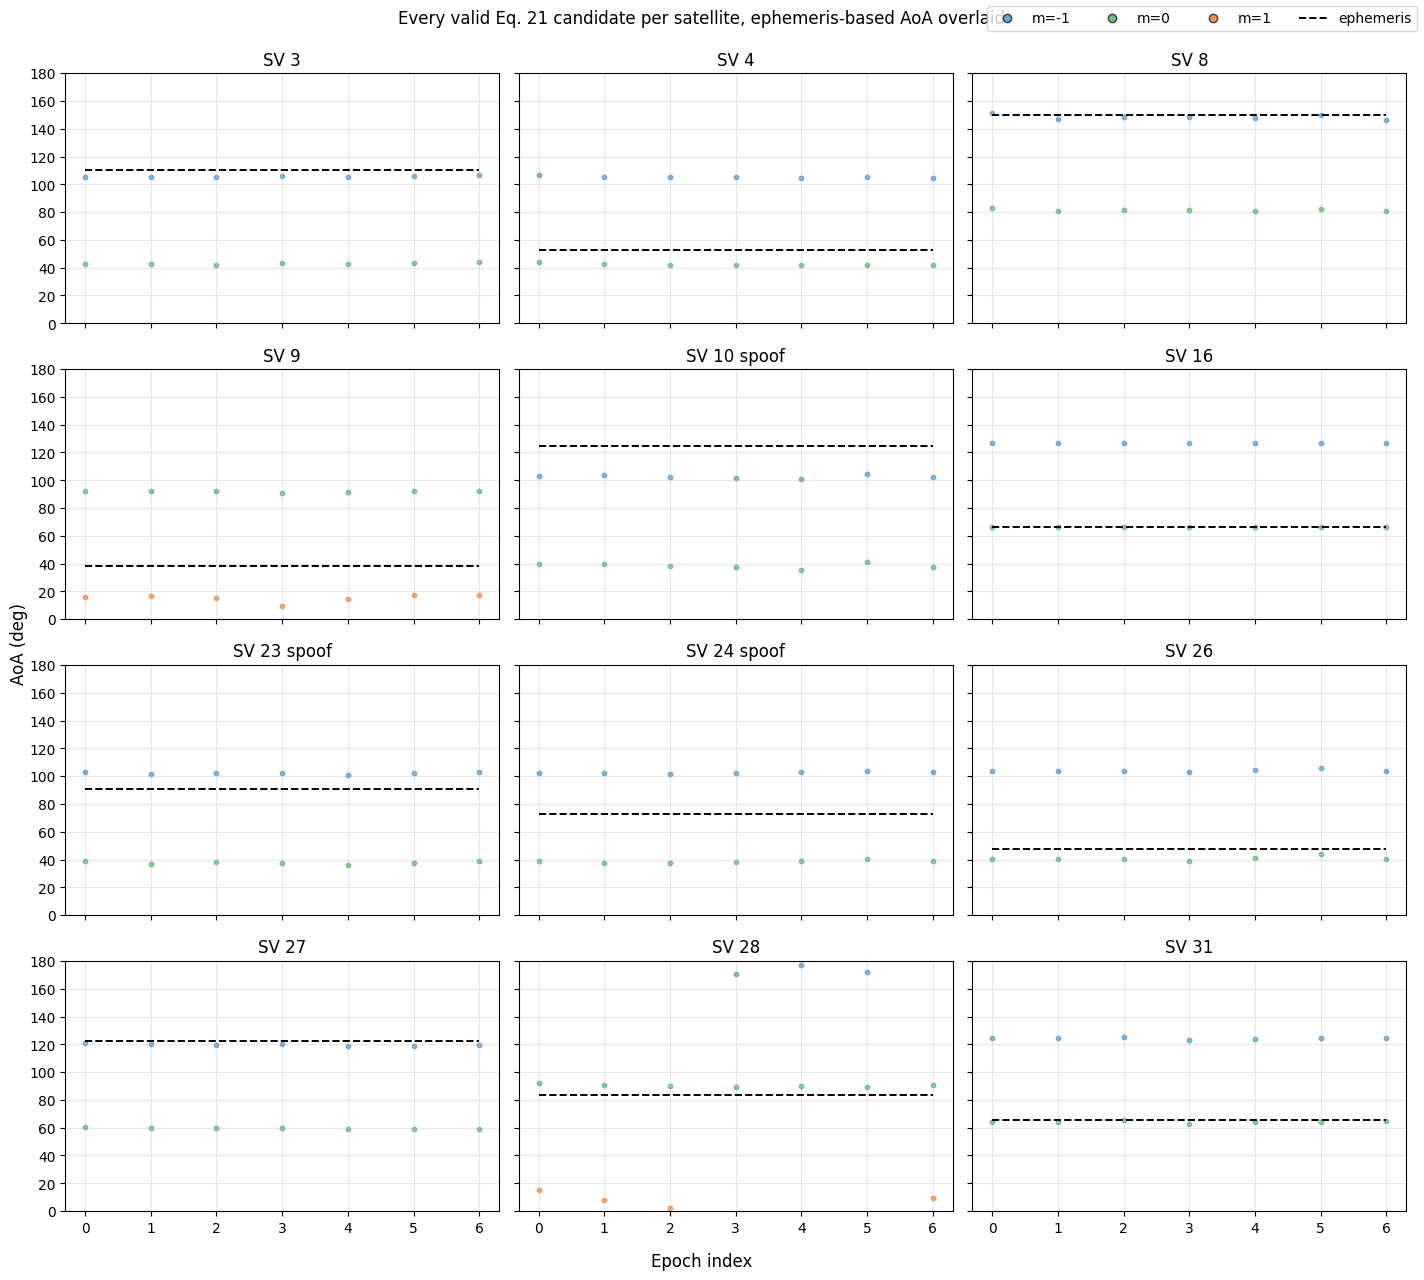

authentic PRNs on their ephemeris-aligned branch: |DD-method AoA - ephemeris-based AoA|


,svid,branch,epoch_count,median_abs_error_deg,within_10deg_fraction
1,3,-1,7,4.86,1.00
3,4,0,7,10.28,0.29
5,8,-1,7,1.61,1.00
7,9,1,7,21.72,0.00
11,16,0,7,0.00,1.00
17,26,0,7,6.71,1.00
19,27,-1,7,2.73,1.00
21,28,0,7,6.70,1.00
23,31,0,7,1.14,1.00


authentic PRNs within 10 deg of ephemeris on one branch: 7 of 9
svUsed over the full NAV-SAT timeline of both receivers


,receiver,svid,total_epoch_count,observed_epoch_count,used_epoch_count,pct_observed_epochs_used,first_used_epoch_index,last_used_epoch_index
0,Receiver 1,10,402,402,0,0.000000,NaN,NaN
1,Receiver 1,23,402,402,0,0.000000,NaN,NaN
2,Receiver 1,24,402,402,0,0.000000,NaN,NaN
3,Receiver 2,10,374,374,0,0.000000,NaN,NaN
4,Receiver 2,23,374,374,0,0.000000,NaN,NaN
5,Receiver 2,24,374,374,14,3.743316,183.0,344.0


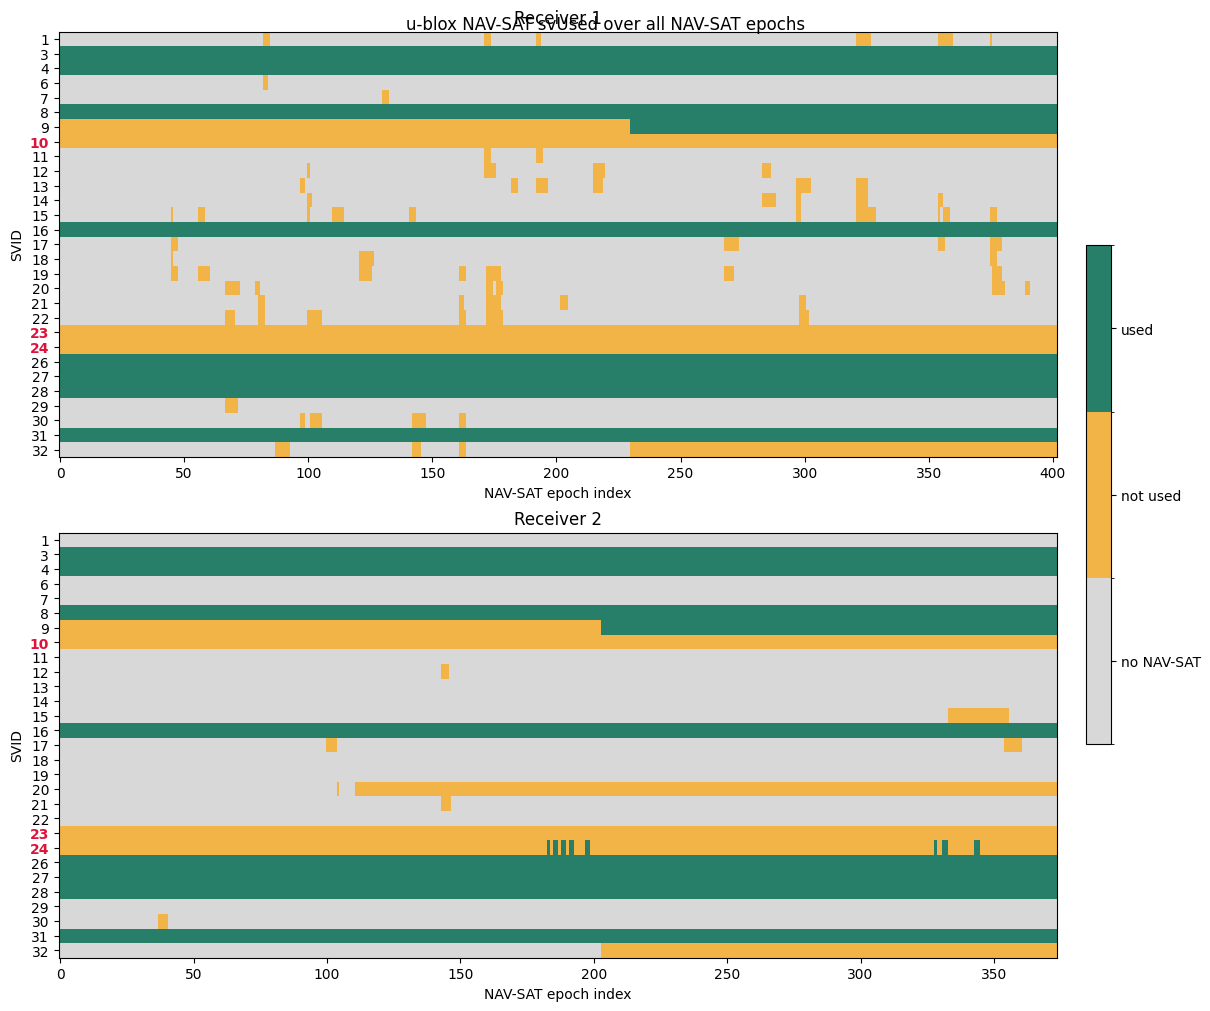

In [7]:
print("analysis window (synchronized epochs)")
display(result.epochs[["epoch_index", "source_epoch_index", "rcvTow_rx1", "rcvTow_rx2", "tow_delta_s"]])
print("reference ranking of the non-spoof PRNs (probe pass)")
display(scenario.probe_result.reference_selection.head(8))
window_anchor = scenario.reference_alpha_by_epoch.loc[
    scenario.reference_alpha_by_epoch["epoch_index"].isin(result.epochs["source_epoch_index"])
]
print(f"reference-angle anchor of PRN {result.reference_svid} inside the window (Receiver 1 NAV-SAT)")
display(
    window_anchor[["reference_elev_deg", "reference_azim_deg", "reference_alpha_deg"]]
    .describe()
    .loc[["count", "mean", "min", "max"]]
    .round(2)
)

print("fractional DD (cycles) of the spoof PRNs inside the window")
display(result.fractional_dd_cycles.round(4))
fig = plot_fractional_dd(all_satellite_result, highlight_svids=USABLE_SPOOF_SVIDS, title="Fractional DD of every PRN inside the window")
display(fig)
plt.close(fig)

fig = plot_aoa_tracks(
    scenario.joint_source_aoa_deg,
    title="Spoof PRNs: joint-source DD-method AoA on the selected branch",
    highlight_svids=USABLE_SPOOF_SVIDS,
)
display(fig)
plt.close(fig)

print("joint-source branch ambiguity per epoch (costs in direction cosine)")
display(scenario.joint_source_ambiguity.round(4))
print("every valid Eq. 21 branch of the spoof PRNs inside the window")
display(scenario.spoof_branch_candidates.round(2))

fig = plot_valid_m_candidates(
    all_satellite_result.candidate_aoa_deg,
    reference_aoa=scenario.ephemeris_aoa_rx1_deg,
    title="Every valid Eq. 21 candidate per satellite, ephemeris-based AoA overlaid",
    highlight_svids=USABLE_SPOOF_SVIDS,
)
display(fig)
plt.close(fig)

equivalence = scenario.aoa_method_equivalence_summary
authentic = equivalence.loc[
    equivalence["method"].eq("ephemeris_aligned_constant_m") & ~equivalence["svid"].isin(SPOOF_SVIDS)
]
print("authentic PRNs on their ephemeris-aligned branch: |DD-method AoA - ephemeris-based AoA|")
display(authentic[["svid", "branch", "epoch_count", "median_abs_error_deg", "within_10deg_fraction"]].round(2))
if not authentic.empty:
    print(
        f"authentic PRNs within {DETECTION_THRESHOLD_DEG:.0f} deg of ephemeris on one branch: "
        f"{int((authentic['median_abs_error_deg'] <= DETECTION_THRESHOLD_DEG).sum())} of {len(authentic)}"
    )

print("svUsed over the full NAV-SAT timeline of both receivers")
display(scenario.sv_used_summary)
fig = plot_sv_used_timeline(
    {"Receiver 1": scenario.sv_used_rx1, "Receiver 2": scenario.sv_used_rx2},
    title="u-blox NAV-SAT svUsed over all NAV-SAT epochs",
    highlight_svids=USABLE_SPOOF_SVIDS,
)
display(fig)
plt.close(fig)

## 6. Outputs and validation

Every table and figure above is saved under `outputs/aoa_paper/<dataset>/`. The checks below fail loudly when an output is missing, a spoof PRN is absent from the result, the automatic reference PRN is a spoof PRN, or a branch was attributed to a prior that was not set.


In [8]:
required_outputs = [
    "paper_capture_message_inventory.csv",
    "paper_capture_spoof_phase.csv",
    "paper_rig_check.csv",
    "paper_spoof_single_difference_collapse.csv",
    "paper_scenario_run_summary.csv",
    "paper_reference_alpha_by_epoch.csv",
    "paper_spoof_joint_source_aoa_deg.csv",
    "paper_spoof_joint_source_branch.csv",
    "paper_spoof_joint_source_ambiguity.csv",
    "paper_spoof_branch_candidates.csv",
    "paper_spoof_branch_detection.csv",
    "paper_spoof_branch_summary.png",
    "paper_spoof_pairwise_convergence.csv",
    "paper_spoof_cluster_summary.csv",
    "paper_spoof_joint_source_dd_method_aoa.png",
    "paper_all_satellite_fractional_dd_cycles.csv",
    "paper_all_satellite_ephemeris_aoa_rx1_deg.csv",
    "paper_all_satellite_valid_m_candidates.png",
    "paper_all_satellite_aoa_method_equivalence_summary.csv",
    "paper_sv_used_summary.csv",
    "paper_sv_used_all_epochs_by_receiver.png",
    "collapse_metrics.csv",
    "fractional_dd_cycles.csv",
]
missing_outputs = [name for name in required_outputs if not (SCENARIO_CONFIG.output_dir / name).exists()]
assert not missing_outputs, f"Missing scenario outputs: {missing_outputs}"

assert len(result.epochs) > 0
assert set(USABLE_SPOOF_SVIDS) == set(scenario.joint_source_aoa_deg.columns.astype(int))
assert set(USABLE_SPOOF_SVIDS) == set(detection["svid"].astype(int))
if REFERENCE_SVID is None:
    assert result.reference_svid not in SPOOF_SVIDS, "automatic reference PRN is a spoof PRN"
else:
    assert result.reference_svid == REFERENCE_SVID
assert ambiguity["chosen_by"] in {"data", "prior", "unresolved"}
if PRIOR_AOA_DEG is None:
    assert ambiguity["chosen_by"] != "prior"
assert scenario.sv_used_rx1.shape[0] >= len(result.epochs)

print(f"Notebook validation: ok; outputs in {SCENARIO_CONFIG.output_dir}")

Notebook validation: ok; outputs in outputs/aoa_paper/sp-partial-28-08/v4
